[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol13_notebook_seminar.ipynb)

# Capitolul 13: Machine Learning în finanțe — Notebook de seminar (Bitcoin)

**Modelarea piețelor financiare (MFM)** · Academia de Studii Economice din București · Daniel Traian Pele, Antoaneta Amza

Probleme pe date zilnice Bitcoin (BTC-USD, 2014–2026) și Ether (ETH-USD, 2015–2026), în corespondență cu
slide-urile Seminarului 13. Problemele **[Rezolvat]** sînt modele lucrate, cu codul complet; problemele
**[Propus]** sînt pentru voi — fiecare urmează unei probleme rezolvate analoage. Fiecare problemă din Partea B se
încheie cu întrebări de interpretare: *ce ar schimba concluzia?*

| Partea | Rezolvate | Propuse |
|---|---|---|
| A — derivări (verificări numerice) | A1 suma ponderilor Fixed-Width Fractional Differencing (FFD), A2 probabilități de atingere a barierelor, A4 varianța Sharpe Ratio (SR) și Probabilistic Sharpe Ratio (PSR)/Deflated Sharpe Ratio (DSR), A3 pierderea prin purjare, A8 Standard Error (SE) pentru Area Under the Curve (AUC) | A5 Augmented Dickey–Fuller (ADF) respinge prea des, A6 bariere cu drift, A10 DSR și constanta Gumbel, A7 purjare, A9 varianța DeLong |
| B — Python | B5 memoria BTC: regula ADF vs local Whittle, B1 trei bariere, B2 validare purjată, B3 modele + Confidence Interval (CI) pentru AUC, B11 meta-etichetare, B6 DSR + $N$ efectiv, B10 Pesaran–Timmermann și Clark–West | B7 memoria ETH (o capcană), B8 bariere asimetrice, B9 găsiți leakage-ul, B4 Diebold–Mariano, B12 Probability of Backtest Overfitting (PBO), B13 Superior Predictive Ability (SPA) vs DSR, B14 selecție dublă |
| C — deschisă | | C2 model fundațional vs boosting, C1 critica unui răspuns generat de inteligență artificială (Artificial Intelligence, AI), C3 Stochastic Discount Factor (SDF) pe decile (slide-uri) |

**Seminarul 13 are loc înaintea cursului 13.** Citiți întîi slide-urile *Ce vă trebuie azi*, apoi lucrați în ordinea:
A1, A2, B1, A3, B2, B3, B4, C1, A4. **După curs:** B5 și B6 (rulați totuși celulele B5: secțiunile următoare
folosesc funcția `min_d_table` și randamentele `r_btc` definite acolo). Toate celelalte secțiuni fac parte din pachetele de extindere opționale.

> Rezolvările se discută la seminar.

> **Lucrul în Google Colab.** Salvați întîi o copie proprie în Drive. Linkul deschide notebook-ul public; modificările devin ale voastre numai în copia salvată. Celula următoare permite salvarea fișierelor produse în Drive; implicit, această opțiune este oprită.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_13'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261017T015255-9bf134


## 0. Configurare și funcții ajutătoare

In [ ]:
import sys
if 'google.colab' in sys.modules:
    !pip -q install shap

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')

# Paleta de culori MFM
MainBlue, IDAred, Forest, Amber = '#1A3A6E', '#CD0000', '#2E7D32', '#B5853F'
Orange, Purple, Gray, LightGray = '#E67E22', '#8E44AD', '#1F2A44', '#C5D2E8'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
                     'font.size': 9, 'axes.titlesize': 10, 'legend.frameon': False,
                     'figure.dpi': 110, 'figure.facecolor': 'none', 'axes.facecolor': 'none',
                     'savefig.facecolor': 'none', 'savefig.transparent': True})
SEED = 42


def legend_bottom(ax, ncol=2, y=-0.25, handles=None, labels=None, **kw):
    """Legenda în afara graficului, jos-centru (stilul graficelor MFM)."""
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False, **kw)

BTC: 2014-09-17 -> 2026-09-18 4385 obs
ETH: 2015-08-07 -> 2026-09-18 4061 obs


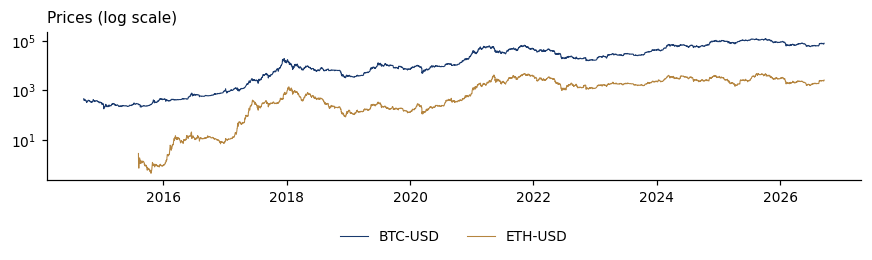

In [ ]:
import os
DATA_URL = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
SERIES = {'sp500': 'GSPC.INDX', 'vix': 'VIX.INDX', 'btc': 'BTC-USD.CC', 'eth': 'ETH-USD.CC'}
START = {'sp500': '2000-01-01', 'vix': '2000-01-01', 'btc': '2014-09-17', 'eth': '2015-08-07'}


def load_data(name='sp500', start=None, end='2026-09-18'):
    """Prețurile OHLCV zilnice din datele cursului."""
    fname = SERIES[name] + '.csv'
    local = [os.path.join(d, 'data', 'market', fname) for d in ('.', '..', '../..', '../../..')]
    path = next((p for p in local if os.path.exists(p)), DATA_URL + fname)
    df = pd.read_csv(path, parse_dates=['date']).set_index('date')
    df = df.rename(columns=str.capitalize)[['Open', 'High', 'Low', 'Close', 'Volume']]
    return df.loc[start or START[name]:end]


btc = load_data('btc')['Close']
log_btc = np.log(btc)
eth = load_data('eth')['Close']
log_eth = np.log(eth)
print('BTC:', btc.index[0].date(), '->', btc.index[-1].date(), len(btc), 'obs')
print('ETH:', eth.index[0].date(), '->', eth.index[-1].date(), len(eth), 'obs')

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(btc.index, btc.values, color=MainBlue, lw=0.7, label='BTC-USD')
ax.plot(eth.index, eth.values, color=Amber, lw=0.7, label='ETH-USD')
ax.set_yscale('log'); ax.set_title('Prices (log scale)', loc='left'); legend_bottom(ax, ncol=2)
plt.tight_layout(); plt.show()

Funcțiile de mai jos (dezvoltate în cursul 13, după seminar; slide-urile *Ce vă trebuie azi* le rezumă) sînt date: diferențiere fracționară, volatilitate Exponentially Weighted Moving Average (EWMA), etichetare
cu trei bariere, K-fold purjat, caracteristici, raportul Sharpe și PSR/DSR. Cripto se tranzacționează 365 de zile pe an, deci anualizăm cu 365.
Rapoartele Sharpe se calculează pe randamente **logaritmice** zilnice (creșterea logaritmică medie pe unitatea de risc); evenimentele fără o fereastră completă de $h$ zile la sfîrșitul eșantionului nu se etichetează.

In [ ]:
def ffd_weights(d, threshold=1e-4, max_size=10_000):
    """w_k = -w_{k-1} (d - k + 1) / k, trunchiate când |w_k| < threshold."""
    w = [1.0]
    for k in range(1, max_size):
        w_k = -w[-1] * (d - k + 1) / k
        if abs(w_k) < threshold:
            break
        w.append(w_k)
    return np.array(w)


def frac_diff_ffd(series, d, threshold=1e-4):
    """Diferențiere fracționară cu fereastră fixă: X~_t = sum_k w_k X_{t-k}."""
    w = ffd_weights(d, threshold)
    x = series.dropna().values
    out = np.convolve(x, w, mode='valid')
    return pd.Series(out, index=series.dropna().index[len(w) - 1:])


def local_whittle(x, m=None, alpha=0.65):
    """Estimatorul local Whittle al memoriei d (Robinson, 1995); întoarce (d_hat, SE = 1/(2 sqrt(m)))."""
    from scipy.optimize import minimize_scalar
    x = np.asarray(x, float); n = len(x); m = m or int(n ** alpha)
    lam = 2 * np.pi * np.arange(1, m + 1) / n
    I = np.abs(np.fft.fft(x - x.mean())[1:m + 1]) ** 2 / (2 * np.pi * n)
    R = lambda d: np.log(np.mean(lam ** (2 * d) * I)) - 2 * d * np.mean(np.log(lam))
    return minimize_scalar(R, bounds=(-0.49, 1.99), method='bounded').x, 1 / (2 * np.sqrt(m))


def exact_local_whittle(x, m=None, alpha=0.65):
    """Local Whittle exact (Shimotsu & Phillips, 2005), valid și pentru d >= 0,5; valoarea inițială scăzută (Shimotsu, 2010)."""
    from scipy.optimize import minimize_scalar
    x = np.asarray(x, float); x = x - x[0]; n = len(x); m = m or int(n ** alpha)
    lam = 2 * np.pi * np.arange(1, m + 1) / n
    k = np.arange(1, n); L = 2 ** int(np.ceil(np.log2(2 * n)))
    def R(d):
        pi = np.concatenate([[1.0], np.cumprod((k - 1 - d) / k)])
        u = np.fft.irfft(np.fft.rfft(x, L) * np.fft.rfft(pi, L), L)[:n]        # (1-B)^d x_t
        I = np.abs(np.fft.fft(u)[1:m + 1]) ** 2 / (2 * np.pi * n)
        return np.log(np.mean(I)) - 2 * d * np.mean(np.log(lam))
    return minimize_scalar(R, bounds=(-0.49, 1.99), method='bounded').x, 1 / (2 * np.sqrt(m))


def get_daily_vol(close, span=50):
    """Volatilitatea EWMA: rădăcina pătrată a mediei EWMA a abaterilor pătratice ale randamentelor log zilnice."""
    return np.log(close).diff().ewm(span=span).std()


def triple_barrier(close, events_idx, vol, pt=1.0, sl=1.0, horizon=10):
    """Etichete cu trei bariere: +1 sus, -1 jos, semnul randamentului la bariera verticală."""
    logp = np.log(close)
    pos = {t: i for i, t in enumerate(close.index)}
    rows = []
    for t0 in events_idx:
        i0 = pos[t0]
        if i0 + horizon >= len(close) or np.isnan(vol.iloc[i0]):
            continue                                   # fereastră de h zile incompletă la sfârșitul eșantionului: cenzurat, omis
        i1 = i0 + horizon
        width = vol.iloc[i0] * np.sqrt(horizon)
        path = logp.iloc[i0 + 1:i1 + 1] - logp.iloc[i0]
        up = path[path >= pt * width].index.min() if pt > 0 else pd.NaT
        dn = path[path <= -sl * width].index.min() if sl > 0 else pd.NaT
        first = min([t for t in (up, dn) if pd.notna(t)], default=pd.NaT)
        if pd.isna(first):
            t1, barrier = close.index[i1], 'vertical'
            label = int(np.sign(path.iloc[-1])) if len(path) else 0
        else:
            t1 = first
            barrier = 'upper' if first == up else 'lower'
            label = 1 if barrier == 'upper' else -1
        rows.append((t0, t1, logp.loc[t1] - logp.iloc[i0], label, barrier, width))
    return pd.DataFrame(rows, columns=['t0', 't1', 'ret', 'label', 'barrier', 'width']).set_index('t0')


def rsi(close, n=14):
    delta = close.diff()
    up = delta.clip(lower=0).ewm(alpha=1 / n).mean()
    dn = (-delta.clip(upper=0)).ewm(alpha=1 / n).mean()
    return 100 - 100 / (1 + up / dn)


def build_features(close, vix=None, d_ffd=None, periods=252):
    """Caracteristici care folosesc doar informația disponibilă la momentul t (fără look-ahead); periods = zile de tranzacționare pe an (252 acțiuni, 365 cripto)."""
    lp = np.log(close)
    r = lp.diff()
    f = pd.DataFrame(index=close.index)
    for h in (1, 5, 20, 60, 120):
        f[f'mom_{h}'] = lp.diff(h)                                     # momentum pe h zile
    f['vol_20'] = r.rolling(20).std() * np.sqrt(periods)
    f['vol_60'] = r.rolling(60).std() * np.sqrt(periods)
    f['vol_ratio'] = f['vol_20'] / f['vol_60']
    f['dist_ma50'] = lp - lp.rolling(50).mean()
    f['dist_ma200'] = lp - lp.rolling(200).mean()
    f['rsi_14'] = rsi(close) / 100
    if vix is not None:
        v = np.log(vix.reindex(close.index).ffill())
        f['vix_level'] = v
        f['vix_chg_5'] = v.diff(5)
    if d_ffd is not None:
        f['ffd_price'] = frac_diff_ffd(lp, d_ffd)
    return f


def sharpe_ratio(returns, periods=252):
    """Sharpe anualizat (rată fără risc zero)."""
    r = np.asarray(returns)
    return np.sqrt(periods) * r.mean() / r.std(ddof=1)


class PurgedKFold:
    """K-Fold fără amestecare pentru etichete suprapuse.

    t1: pd.Series indexată după momentul observației t0, valoare = momentul t1 când eticheta devine cunoscută.
    Purjare: eliminăm din antrenare observațiile al căror [t0, t1] se suprapune cu perioada de test.
    Embargo: eliminăm și o fracțiune pct_embargo de observații imediat după setul de test.
    """

    def __init__(self, n_splits=5, t1=None, pct_embargo=0.01):
        self.n_splits, self.t1, self.pct_embargo = n_splits, t1, pct_embargo

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits

    def split(self, X, y=None, groups=None):
        idx = np.arange(len(X))
        t0, t1 = self.t1.index.values, self.t1.values
        embargo = int(len(X) * self.pct_embargo)
        for test in np.array_split(idx, self.n_splits):
            start, stop = test[0], test[-1]
            test_t0, test_t1 = t0[start], t1[test].max()
            before = idx[t1 < test_t0]                                  # etichete cunoscute înainte de test
            after_start = min(stop + 1 + embargo, len(X))               # embargo
            after = idx[after_start:][t0[after_start:] > test_t1]       # încep după ultima etichetă de test
            yield np.concatenate([before, after]), test


EULER_GAMMA = 0.5772156649015329


def probabilistic_sharpe_ratio(sr, sr_benchmark, T, skew=0.0, kurt=3.0):
    """PSR(SR*) = Phi((SR - SR*) sqrt(T-1) / sqrt(1 - g3 SR + (g4 - 1)/4 SR^2)); SR pe perioadă, kurt = kurtosis brut (distribuția Normală = 3)."""
    denom = np.sqrt(1 - skew * sr + (kurt - 1) / 4 * sr ** 2)
    return stats.norm.cdf((sr - sr_benchmark) * np.sqrt(T - 1) / denom)


def expected_max_sharpe(n_trials, sr_std=1.0):
    """Teorema strategiei false: E[max SR] ~ sqrt(V[SR]) ((1-g) Phi^-1(1-1/N) + g Phi^-1(1-1/(N e)))."""
    n = np.asarray(n_trials, dtype=float)
    return sr_std * ((1 - EULER_GAMMA) * stats.norm.ppf(1 - 1 / n)
                     + EULER_GAMMA * stats.norm.ppf(1 - 1 / (n * np.e)))


def deflated_sharpe_ratio(sr, T, n_trials, sr_std, skew=0.0, kurt=3.0):
    """DSR = PSR(SR_0), SR_0 = E[max SR] sub ipoteza nulă de lipsă a abilității."""
    return probabilistic_sharpe_ratio(sr, expected_max_sharpe(n_trials, sr_std), T, skew, kurt)


## Partea A — verificări numerice ale problemelor pe hîrtie

### A1 [Rezolvat] — ponderile FFD, sumele lor parțiale și lungimea ferestrei

In [ ]:
from scipy.special import gamma as G
print(np.round(ffd_weights(0.5, threshold=0, max_size=5), 7))
d, tau = 0.25, 1e-4
w = ffd_weights(d, tau); K = len(w) - 1
print(f'd = {d}: K = {K}, aproximarea (tau |Gamma(-d)|)^(-1/(1+d)) = {(tau * abs(G(-d))) ** (-1 / (1 + d)):.0f}')
from scipy.special import gammaln
print(f'suma ponderilor = {w.sum():.4f}; Gamma(K+1-d)/(Gamma(1-d)Gamma(K+1)) = {np.exp(gammaln(K + 1 - d) - gammaln(1 - d) - gammaln(K + 1)):.4f}; '
      f'K^(-d)/Gamma(1-d) = {K ** (-d) / G(1 - d):.4f}')

[ 1.        -0.5       -0.125     -0.0625    -0.0390625]
d = 0.25: K = 444, aproximarea (tau |Gamma(-d)|)^(-1/(1+d)) = 444
suma ponderilor = 0.1777; Gamma(K+1-d)/(Gamma(1-d)Gamma(K+1)) = 0.1777; K^(-d)/Gamma(1-d) = 0.1778


### A5 [Propus] — lungimea ferestrei, suma ponderilor și respingerile ADF prea dese pentru $d = 0{,}3$ și $d = 0{,}5$

In [ ]:
# Codul vostru aici


### A2 [Rezolvat] — etichetele cu trei bariere a două traiectorii scurte

In [ ]:
def label_path(path, sigma, h, pt, sl):
    """Eticheta cu trei bariere a unei traiectorii (path[0] = prețul de intrare)."""
    width = sigma * np.sqrt(h)
    up, dn = path[0] * np.exp(pt * width), path[0] * np.exp(-sl * width)
    for day, p_ in enumerate(path[1:], start=1):
        if p_ >= up:
            return +1, day, round(up, 2), round(dn, 2)
        if p_ <= dn:
            return -1, day, round(up, 2), round(dn, 2)
    return int(np.sign(np.log(path[-1] / path[0]))), len(path) - 1, round(up, 2), round(dn, 2)

for path in ([100, 101.0, 100.4, 102.5, 101.2, 99.8], [100, 99.2, 98.6, 99.5, 98.9, 99.1]):
    print(label_path(path, 0.01, 5, 1, 1))

# Repere browniene: probabilitatea de ieșire la bariera verticală pentru bariere simetrice +-sigma sqrt(h), h = 10 zile
def p_no_touch(c, terms=50):
    # P(|W_s| < c for all s <= 1), c = barrier / (sigma sqrt(h))
    n = np.arange(terms)
    return 4 / np.pi * np.sum((-1) ** n / (2 * n + 1) * np.exp(-(2 * n + 1) ** 2 * np.pi ** 2 / (8 * c ** 2)))
print(f'monitorizare continuă: {p_no_touch(1.0):.3f}; '
      f'monitorizare zilnică, barieră mutată cu 0,5826 sigma: {p_no_touch(1 + 0.5826 / np.sqrt(10)):.3f}')

(1, 3, np.float64(102.26), np.float64(97.79))
(-1, 5, np.float64(102.26), np.float64(97.79))
monitorizare continuă: 0.371; monitorizare zilnică, barieră mutată cu 0,5826 sigma: 0.528


### A6 [Propus] — bariere asimetrice, $pt = 2$, $sl = 1$

In [ ]:
# Codul vostru aici


### A4 [Rezolvat] — PSR și DSR ($SR_{an} = 1{,}2$, $T = 756$, $N = 100$)

In [ ]:
sr, T = 1.2 / np.sqrt(252), 756
print(f'PSR(0) = {probabilistic_sharpe_ratio(sr, 0, T, -0.4, 5):.3f}')
sr0 = expected_max_sharpe(100, np.sqrt(1 / T))
print(f'SR0 = {sr0:.4f} (an. {sr0 * np.sqrt(252):.2f}); DSR = {deflated_sharpe_ratio(sr, T, 100, np.sqrt(1 / T), -0.4, 5):.3f}')

PSR(0) = 0.979
SR0 = 0.0920 (an. 1.46); DSR = 0.329


### A10 [Propus] — PSR și DSR ($SR_{an} = 1{,}5$, $T = 504$, $N = 20$)

In [ ]:
# Codul vostru aici


### A3 [Rezolvat] — purjare și embargo ($t_1 = i + 3$, foldul de test $\{8,\dots,11\}$)

In [ ]:
def removed_sets(h):
    n = 20
    t1 = pd.Series(np.minimum(np.arange(n) + h, n - 1), index=np.arange(n))
    for tr, te in PurgedKFold(5, t1=t1, pct_embargo=0.05).split(np.zeros(n)):
        print('test', list(te), '| eliminate', sorted(set(range(n)) - set(tr) - set(te)), '| antrenare', len(tr))

removed_sets(3)

test [np.int64(0), np.int64(1), np.int64(2), np.int64(3)] | eliminate [4, 5, 6] | antrenare 13
test [np.int64(4), np.int64(5), np.int64(6), np.int64(7)] | eliminate [1, 2, 3, 8, 9, 10] | antrenare 10
test [np.int64(8), np.int64(9), np.int64(10), np.int64(11)] | eliminate [5, 6, 7, 12, 13, 14] | antrenare 10
test [np.int64(12), np.int64(13), np.int64(14), np.int64(15)] | eliminate [9, 10, 11, 16, 17, 18] | antrenare 10
test [np.int64(16), np.int64(17), np.int64(18), np.int64(19)] | eliminate [13, 14, 15] | antrenare 13


### A7 [Propus] — purjare cu $t_1 = i + 2$ (foldul de test $\{12,\dots,15\}$)

In [ ]:
# Codul vostru aici


### A8 [Rezolvat] — AUC pas cu pas și eroarea standard Hanley–McNeil

In [ ]:
def auc_by_hand(pos, neg):
    U = sum((p_ > q_) + 0.5 * (p_ == q_) for p_ in pos for q_ in neg)
    A = U / (len(pos) * len(neg))
    Q1, Q2 = A / (2 - A), 2 * A ** 2 / (1 + A)
    se = np.sqrt((A * (1 - A) + (len(pos) - 1) * (Q1 - A ** 2) + (len(neg) - 1) * (Q2 - A ** 2)) / (len(pos) * len(neg)))
    return U, round(A, 4), round(se, 3), round((A - 0.5) / se, 2)

print('U, AUC, SE, z =', auc_by_hand([0.80, 0.55, 0.40], [0.60, 0.35, 0.20]))

U, AUC, SE, z = (7.0, 0.7778, np.float64(0.207), np.float64(1.34))


### A9 [Propus] — AUC pas cu pas (4 pozitive, 4 negative)

In [ ]:
# Codul vostru aici


## B5 [Rezolvat] — Memoria log-prețului BTC: regula ADF vs local Whittle

**Cerință.** Pentru $d \in \{0; 0{,}05; \dots; 1\}$ calculați seria FFD a log-prețului BTC ($\tau = 10^{-4}$),
aplicați testul ADF (cu constantă, 1 lag) și rețineți statistica, valoarea critică la 5% și corelația cu
log-prețul inițial. Găsiți cel mai mic $d^*$ pentru care se respinge rădăcina unitară la 5%. Apoi estimați memoria direct: local Whittle exact
pentru log-preț și seria FFD, local Whittle pentru randamente și randamentele absolute, cu CI 95% ($m = n^{0{,}65}$).

**Interpretare.** Este $\hat d$ al log-prețului semnificativ diferit de 1? Este seria FFD la $d^*$ staționară? Ce ar schimba $d^*$?

**Rezolvare.**

d* (BTC) = 0.25, corelația cu log-prețul = 0.955


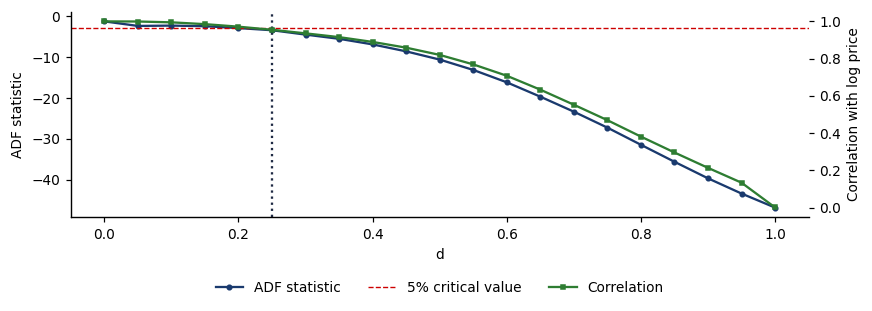

,adf,crit_5%,p_value,corr,n_obs
d,,,,,
0.00,-1.207,-2.862,0.671,1.000,4385
0.05,-2.321,-2.862,0.165,0.999,4024
0.10,-2.240,-2.862,0.192,0.995,3883
0.15,-2.389,-2.862,0.145,0.985,3859
0.20,-2.851,-2.862,0.051,0.972,3889
0.25,-3.376,-2.862,0.012,0.955,3941
0.30,-4.447,-2.862,0.000,0.936,3998
0.35,-5.478,-2.862,0.000,0.915,4054
0.40,-6.847,-2.862,0.000,0.890,4104


In [ ]:
def min_d_table(logp, regression='c'):
    rows = []
    for d in np.round(np.arange(0, 1.01, 0.05), 2):
        x = frac_diff_ffd(logp, d).dropna()
        res = adfuller(x, maxlag=1, regression=regression, autolag=None)
        rows.append((d, res[0], res[4]['5%'], res[1], np.corrcoef(logp.loc[x.index], x)[0, 1], len(x)))
    t = pd.DataFrame(rows, columns=['d', 'adf', 'crit_5%', 'p_value', 'corr', 'n_obs']).set_index('d')
    return t, t.index[t['adf'] < t['crit_5%']].min()

ex1, d_star_btc = min_d_table(log_btc)
print(f'd* (BTC) = {d_star_btc}, corelația cu log-prețul = {ex1.loc[d_star_btc, "corr"]:.3f}')

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ex1.index, ex1['adf'], 'o-', ms=3, color=MainBlue, label='ADF statistic')
ax.axhline(ex1['crit_5%'].iloc[0], color=IDAred, ls='--', lw=0.9, label='5% critical value')
ax.axvline(d_star_btc, color=Gray, ls=':')
ax2 = ax.twinx(); ax2.plot(ex1.index, ex1['corr'], 's-', ms=3, color=Forest, label='Correlation'); ax2.set_ylim(-0.05, 1.05)
ax.set_xlabel('d'); ax.set_ylabel('ADF statistic'); ax2.set_ylabel('Correlation with log price')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
legend_bottom(ax, ncol=3, handles=h1 + h2, labels=l1 + l2)
plt.tight_layout(); plt.show()
ex1.round(3)

In [ ]:
# memoria estimată direct, cu CI 95% (m = n^0,65)
w_b = ffd_weights(d_star_btc)
print(f'suma ponderilor FFD la d* = {d_star_btc}: {w_b.sum():.3f}')
r_btc = log_btc.diff().dropna()
mem_b = {}
for lab, v, est in (('log price (ELW)', log_btc.values, exact_local_whittle),
                    (f'FFD d*={d_star_btc} (ELW)', frac_diff_ffd(log_btc, d_star_btc).values, exact_local_whittle),
                    ('returns (LW)', r_btc.values, local_whittle), ('|returns| (LW)', r_btc.abs().values, local_whittle)):
    dh, se = est(v)
    mem_b[lab] = (dh, dh - 1.96 * se, dh + 1.96 * se)
    print(f'{lab:22s} d_hat = {dh:.3f}, 95% CI [{dh - 1.96 * se:.3f}; {dh + 1.96 * se:.3f}]')
dh, se = exact_local_whittle(log_btc.values)
print(f'H0: d = 1 pentru log-preț: z = {(dh - 1) / se:.2f}')

suma ponderilor FFD la d* = 0.25: 0.178
log price (ELW)        d_hat = 1.065, 95% CI [1.000; 1.129]
FFD d*=0.25 (ELW)      d_hat = 0.814, 95% CI [0.747; 0.880]
returns (LW)           d_hat = 0.063, 95% CI [-0.002; 0.127]
|returns| (LW)         d_hat = 0.353, 95% CI [0.289; 0.417]
H0: d = 1 pentru log-preț: z = 1.97


## B7 [Propus] — Memoria Ether: o capcană

**Cerință.** Pe log-închiderile ETH-USD, trei specificații, fiecare cu scanarea completă a grilei $d \in \{0; 0{,}05; \dots; 1\}$ și un lag ADF (model: B5):

| Rînd | Eșantion | Termeni deterministici | Valoarea critică 5% |
|---|---|---|---|
| 1 | 2015-08-07 – 2026-09-18 ($n = 4\,061$) | constantă | $-2{,}86$ |
| 2 | 2015-08-07 – 2026-09-18 | constantă + trend (`regression='ct'`) | $-3{,}41$ |
| 3 | 2018-01-01 – 2026-09-18 ($n = 3\,183$) | constantă | $-2{,}86$ |

1. Pentru fiecare rînd, găsiți $d^*$ și notați valorile ADF la $d = 0$ și $d = 0{,}05$.
2. Estimați ELW cu CI 95% pentru log-preț pe rîndurile 1 și 3.
3. Estimați LW cu CI 95% pentru $|r_t|$ pe tot eșantionul.

**Raportați.** Un tabel cu $d^*$ și cele două valori ADF pe fiecare rînd; cele două estimări ELW și estimarea LW, cu CI.

**Interpretare.** Ce $d^*$ ați folosi într-un model și de ce? Ce spune asta despre testele de rădăcină unitară pe
active care au crescut de 1.000 de ori?

In [ ]:
# Codul vostru aici


## B1 [Rezolvat] — Etichete cu trei bariere pe BTC, $h=10$, pt = sl $\in\{1,2\}$

**Cerință.** Folosind o volatilitate EWMA (span 50), etichetați fiecare zi din eșantionul BTC prin metoda
celor trei bariere, cu bariera verticală $h = 10$ zile și bariere orizontale simetrice pt = sl $\in\{1, 2\}$
(în unități de $\sigma_{t_0}\sqrt h$). Raportați ponderea atingerilor barierei superioare / inferioare / verticale
și durata medie de deținere, apoi comparați cu etichetele cu orizont fix de 10 zile.

**Interpretare.** De ce circa 56% dintre etichete sînt $+1$ și care este atunci acuratețea de referință a unui clasificator?

**Rezolvare.**

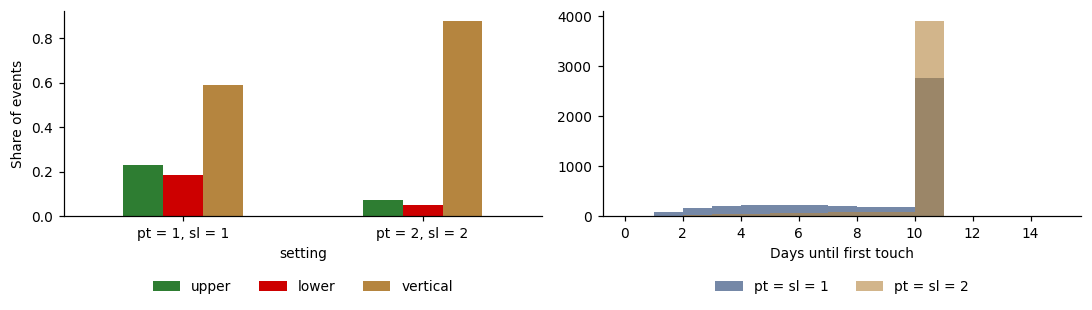

,upper,lower,vertical,avg_days,share_+1
setting,,,,,
"pt = 1, sl = 1",0.228,0.182,0.590,8.248,0.557
"pt = 2, sl = 2",0.072,0.049,0.879,9.581,0.556
orizont fix 10z,NaN,NaN,1.000,10.000,0.555


In [ ]:
vol_b = get_daily_vol(btc)
events = btc.index                                   # fiecare zi este un eveniment
fixed = np.sign(log_btc.shift(-10) - log_btc).reindex(events)


def barrier_table(settings):
    rows, tbs = [], {}
    for pt_, sl_ in settings:
        tb = triple_barrier(btc, events, vol_b, pt=pt_, sl=sl_, horizon=10)
        tbs[(pt_, sl_)] = tb
        share = tb['barrier'].value_counts(normalize=True).reindex(['upper', 'lower', 'vertical']).fillna(0)
        rows.append((f'pt = {pt_}, sl = {sl_}', share['upper'], share['lower'], share['vertical'],
                     (tb['t1'] - tb.index).dt.days.mean(), (tb['label'] > 0).mean()))
    return pd.DataFrame(rows, columns=['setting', 'upper', 'lower', 'vertical', 'avg_days', 'share_+1']).set_index('setting'), tbs

ex3, tbs = barrier_table([(1, 1), (2, 2)])
fx = fixed.reindex(tbs[(1, 1)].index).dropna()                # aceleași evenimente, fereastră completă de 10 zile
ex3.loc['orizont fix 10z'] = [np.nan, np.nan, 1.0, 10.0, (fx > 0).mean()]

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
ex3.iloc[:2][['upper', 'lower', 'vertical']].plot.bar(ax=axes[0], color=[Forest, IDAred, Amber], rot=0, legend=False)
axes[0].set_ylabel('Share of events'); legend_bottom(axes[0], ncol=3)
for k, c in zip(tbs, (MainBlue, Amber)):
    axes[1].hist((tbs[k]['t1'] - tbs[k].index).dt.days, bins=np.arange(0, 16), alpha=0.6, color=c, label=f'pt = sl = {k[0]}')
axes[1].set_xlabel('Days until first touch'); legend_bottom(axes[1], ncol=2)
plt.tight_layout(); plt.show()
ex3.round(3)

## B8 [Propus] — Bariere asimetrice pe BTC

**Cerință.** Repetați B1 cu $(pt, sl) = (2, 1)$ și $(1, 2)$; raportați ponderile ieșirilor, ponderea etichetelor $+1$ și
durata medie de deținere. Comparați ponderea ieșirilor sus între ieșirile orizontale cu $\frac{sl}{pt+sl}$ (A2, fără bariera verticală) și cu un
reper simulat cu orizont finit (pași zilnici gaussieni, aceleași bariere, bariera verticală la $h = 10$).

**Raportați.** Un tabel cu ponderile ieșirilor, ponderea $+1$ și durata medie pentru ambele variante; ponderea ieșirilor sus, cu valoarea teoretică și cele simulate, cu SE.

**Interpretare.** Ce variantă ar alege un trend-follower? Cum schimbă alegerea echilibrul claselor pe care îl vede un clasificator?

In [ ]:
# Codul vostru aici


## B2 [Rezolvat] — Verificarea PurgedKFold și comparația cu K-Fold cu amestecare pe setul „leakage"

**Cerință.** (a) Verificați clasa dată `PurgedKFold(n_splits, t1, pct_embargo)` (celula cu funcții): găsiți linia care purjează
înainte de pliul de test, linia care aplică embargoul și pe cea care purjează după el; rulați-o pe exemplul din A3. (b) Pe setul „leakage" de mai jos (un mers aleator: nu există
nimic de prezis), comparați acuratețea out-of-fold a unui random forest pentru K-Fold cu amestecare, K-Fold fără amestecare și PurgedKFold.

**Interpretare.** S-ar reduce diferența cu caracteristici nepersistente? Cu etichete pe 1 zi?

In [ ]:
# Setul de date „leakage" (dat)
rng = np.random.default_rng(SEED)
n, h = 3000, 20
p = pd.Series(np.cumsum(rng.normal(0, 0.01, n + h)))
y_leak = (p.shift(-h) - p > 0).astype(int).iloc[:n].values          # etichete suprapuse pe 20 de zile
X_leak = np.column_stack([pd.Series(rng.normal(size=n + h)).rolling(h).mean().bfill().iloc[:n] for _ in range(5)])
t1_leak = pd.Series(np.arange(n) + h, index=np.arange(n))            # eticheta obs. i se cunoaște la i + h

**Rezolvare.**

test [np.int64(0), np.int64(1), np.int64(2), np.int64(3)] | eliminate [4, 5, 6] | antrenare 13
test [np.int64(4), np.int64(5), np.int64(6), np.int64(7)] | eliminate [1, 2, 3, 8, 9, 10] | antrenare 10
test [np.int64(8), np.int64(9), np.int64(10), np.int64(11)] | eliminate [5, 6, 7, 12, 13, 14] | antrenare 10
test [np.int64(12), np.int64(13), np.int64(14), np.int64(15)] | eliminate [9, 10, 11, 16, 17, 18] | antrenare 10
test [np.int64(16), np.int64(17), np.int64(18), np.int64(19)] | eliminate [13, 14, 15] | antrenare 13


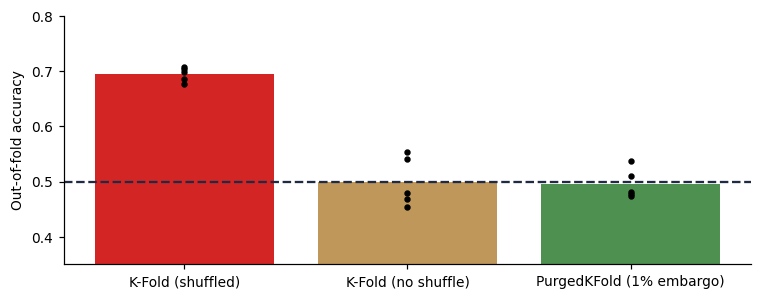

,0
K-Fold (shuffled),0.695
K-Fold (no shuffle),0.499
PurgedKFold (1% embargo),0.496


In [ ]:
# (a) Verificarea PurgedKFold.split:
#   purjare înainte de pliul de test:  before = idx[t1 < test_t0]
#   embargo:                                             after_start = min(stop + 1 + embargo, len(X))
#   purjare după embargo:                 t0[after_start:] > test_t1
removed_sets(3)                                                      # exemplul A3: pliul de test {8, ..., 11} elimină {5, 6, 7, 12, 13, 14}

# (b) Experimentul de leakage
schemes = {'K-Fold (shuffled)': KFold(5, shuffle=True, random_state=SEED),
           'K-Fold (no shuffle)': KFold(5, shuffle=False),
           'PurgedKFold (1% embargo)': PurgedKFold(5, t1=t1_leak, pct_embargo=0.01)}
model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
ex5 = {}
for name, cv_ in schemes.items():
    ex5[name] = [accuracy_score(y_leak[te], model.fit(X_leak[tr], y_leak[tr]).predict(X_leak[te]))
                 for tr, te in cv_.split(X_leak)]
ex5 = pd.DataFrame(ex5)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(range(3), ex5.mean(), color=[IDAred, Amber, Forest], alpha=0.85)
for i, col in enumerate(ex5):
    ax.scatter(np.full(5, i), ex5[col], color='black', s=10, zorder=3)
ax.axhline(0.5, color=Gray, ls='--'); ax.set_xticks(range(3), ex5.columns); ax.set_ylim(0.35, 0.8); ax.set_ylabel('Out-of-fold accuracy')
plt.tight_layout(); plt.show()
ex5.mean().round(3)

## B9 [Propus] — Găsiți leakage-ul

**Cerință.** Celula de mai jos adaugă o a 12-a caracteristică, `ma11`, setului din B3. Cu validare **purjată** în 5 folduri,
random forest-ul atinge acum o acuratețe spectaculoasă pentru direcția BTC la 5 zile. Purjarea nu a oprit-o: găsiți
leakage-ul (citiți cum e construită `ma11` și ordonați caracteristicile după Mean Decrease in Impurity (MDI)), corectați-o și raportați rezultatul onest.

**Interpretare.** De ce nu poate purjarea să prindă acest tip de leakage? Dați un al doilea exemplu de look-ahead bias într-un flux de caracteristici.

In [ ]:
# Cadrul de modelare comun pentru B3, B4, B9 (dat)
H = 5
feats_b = build_features(btc, periods=365)
FB = list(feats_b.columns)
dfb = feats_b.assign(fwd=log_btc.shift(-H) - log_btc).dropna()
dfb['y'] = (dfb['fwd'] > 0).astype(int)
pos = np.searchsorted(btc.index, dfb.index)
dfb['t1'] = btc.index[np.minimum(pos + H, len(btc) - 1)]
Xb, yb = dfb[FB].values, dfb['y'].values

# caracteristica suspectă (dată)
r1 = log_btc.diff()
df6 = dfb.copy()
df6['ma11'] = r1.rolling(11, center=True).mean().reindex(df6.index)
df6 = df6.dropna()
rf6 = RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features='sqrt', n_jobs=-1, random_state=SEED)
cv6 = PurgedKFold(5, t1=df6['t1'], pct_embargo=0.01)


def purged_oos(cols):
    Xs, ys = df6[cols].values, df6['y'].values
    pr = np.full(len(ys), np.nan)
    for tr, te in cv6.split(Xs):
        pr[te] = rf6.fit(Xs[tr], ys[tr]).predict_proba(Xs[te])[:, 1]
    return accuracy_score(ys, pr > 0.5), roc_auc_score(ys, pr)

acc, auc = purged_oos(FB + ['ma11'])
print(f'cu ma11: acuratețe {acc:.3f}, AUC {auc:.3f}')

cu ma11: acuratețe 0.789, AUC 0.875


In [ ]:
# Codul vostru aici


## B3 [Rezolvat] — Logit-L1 vs Random Forest vs Gradient Boosting, importanța caracteristicilor și un CI pentru AUC

**Cerință.** Comparați o regresie logistică penalizată $L_1$, un random forest și gradient boosting pentru direcția BTC la 5 zile,
cu validare **purjată** în 5 folduri (embargo 1%): acuratețe, Receiver Operating Characteristic (ROC) AUC și reperul „mereu în sus"; comparați MDI, Mean Decrease in Accuracy (MDA) și media |SHapley Additive exPlanations (SHAP)|.
Apoi luați probabilitățile out-of-fold agregate ale random forest-ului și calculați de două ori un CI de 95% pentru AUC: cu eroarea
standard DeLong (observații independente) și cu bootstrap circular pe blocuri ($L = 1, 20, 60$; 1.000 de replici).

**Raportați (măsurile de importanță).** Un grafic cu cele trei măsuri pe caracteristici și tabelul corelațiilor Spearman.

**Interpretare.** De ce e intervalul bootstrap mai larg? Ce lungime de bloc ați apăra?

**Rezolvare.**

In [ ]:
print(dfb.shape, '| share up =', round(yb.mean(), 3))
models = {
    'Logit-L1': make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', C=0.05, solver='liblinear', random_state=SEED)),
    'Random Forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=50, max_features='sqrt',
                                            n_jobs=-1, random_state=SEED),
    'Gradient Boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.03, max_iter=200,
                                                        min_samples_leaf=50, random_state=SEED),
}
cv = PurgedKFold(5, t1=dfb['t1'], pct_embargo=0.01)
oos = {k: np.full(len(yb), np.nan) for k in models}
const = np.full(len(yb), np.nan)                     # prognoză constantă: ponderea zilelor „sus" din antrenare
rows = []
for name, m in models.items():
    acc, auc, base = [], [], []
    for tr, te in cv.split(Xb):
        prob = m.fit(Xb[tr], yb[tr]).predict_proba(Xb[te])[:, 1]
        oos[name][te] = prob
        const[te] = yb[tr].mean()
        acc.append(accuracy_score(yb[te], prob > 0.5)); auc.append(roc_auc_score(yb[te], prob))
        base.append(yb[te].mean())                # acuratețea "mereu în sus" = proporția etichetelor "sus" din pliul de test
    rows.append((name, np.mean(acc), np.std(acc), np.mean(auc), np.std(auc), np.mean(base)))
ex7 = pd.DataFrame(rows, columns=['model', 'accuracy', 'acc_sd', 'AUC', 'auc_sd', 'always_up']).set_index('model')
ex7.round(3)

(4181, 14) | share up = 0.548


,accuracy,acc_sd,AUC,auc_sd,always_up
model,,,,,
Logit-L1,0.548,0.037,0.492,0.025,0.548
Random Forest,0.542,0.027,0.516,0.036,0.548
Gradient Boosting,0.522,0.022,0.502,0.023,0.548


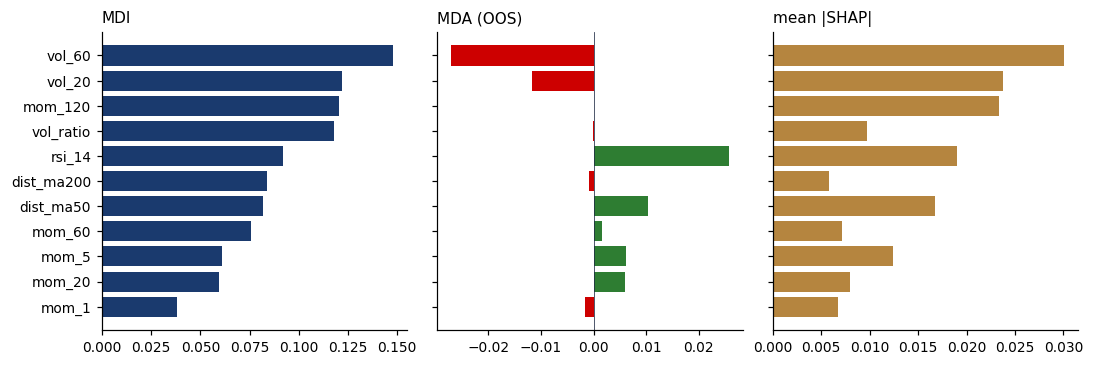

Corelații de rang Spearman:
       MDI   MDA  SHAP
MDI   1.00 -0.42  0.75
MDA  -0.42  1.00 -0.10
SHAP  0.75 -0.10  1.00


In [ ]:
split = int(len(dfb) * 0.7)
gap = split + H + int(0.01 * len(dfb))
Xbdf = dfb[FB]
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=50, max_features='sqrt',
                            n_jobs=-1, random_state=SEED).fit(Xbdf.iloc[:split], yb[:split])
mdi = pd.Series(rf.feature_importances_, index=FB)
mda = pd.Series(permutation_importance(rf, Xbdf.iloc[gap:], yb[gap:], scoring='roc_auc', n_repeats=10,
                                       random_state=SEED, n_jobs=-1).importances_mean, index=FB)
try:
    import shap
    sv = shap.TreeExplainer(rf).shap_values(Xbdf.iloc[gap:].sample(300, random_state=SEED))
    sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if np.ndim(sv) == 3 else sv)
    shp = pd.Series(np.abs(sv).mean(0), index=FB)
except Exception as e:
    print('SHAP skipped:', e)
    shp = pd.Series(np.nan, index=FB)
imp_b = pd.DataFrame({'MDI': mdi, 'MDA': mda, 'SHAP': shp}).sort_values('MDI')

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
axes[0].barh(imp_b.index, imp_b['MDI'], color=MainBlue); axes[0].set_title('MDI', loc='left')
axes[1].barh(imp_b.index, imp_b['MDA'], color=np.where(imp_b['MDA'] > 0, Forest, IDAred))
axes[1].axvline(0, color=Gray, lw=0.5); axes[1].set_title('MDA (OOS)', loc='left')
axes[2].barh(imp_b.index, imp_b['SHAP'], color=Amber); axes[2].set_title('mean |SHAP|', loc='left')
plt.tight_layout(); plt.show()
print('Corelații de rang Spearman:')
print(imp_b.corr(method='spearman').round(2))

RF pooled AUC = 0.512; DeLong SE = 0.0090, CI [0.495; 0.530], z = 1.37, p = 0.169


L =  1: SE = 0.0091, CI [0.494; 0.530], ponderea replicilor <= 0,5 = 0.079


L = 20: SE = 0.0150, CI [0.484; 0.543], ponderea replicilor <= 0,5 = 0.208


L = 60: SE = 0.0141, CI [0.485; 0.541], ponderea replicilor <= 0,5 = 0.186


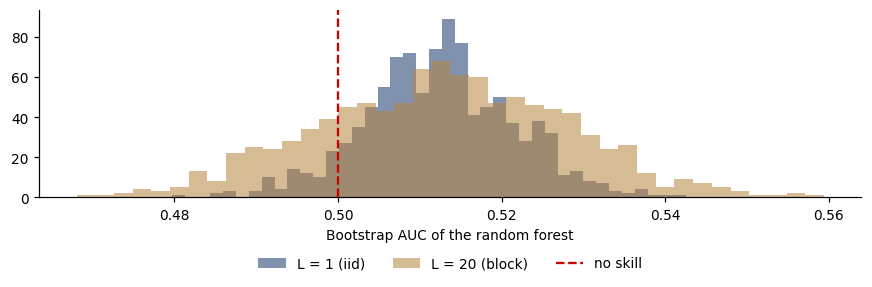

In [ ]:
def delong_auc(y, s):
    """AUC și varianța DeLong (observații independente)."""
    pos, neg = s[y == 1], s[y == 0]
    m1, n0 = len(pos), len(neg)
    rk = stats.rankdata(np.concatenate([pos, neg]))
    auc = (rk[:m1].sum() - m1 * (m1 + 1) / 2) / (m1 * n0)
    v10 = (rk[:m1] - stats.rankdata(pos)) / n0
    v01 = 1 - (rk[m1:] - stats.rankdata(neg)) / m1
    return auc, np.var(v10, ddof=1) / m1 + np.var(v01, ddof=1) / n0


def cbb_index(n, L, rng):
    """Indici bootstrap circular pe blocuri, lungimea blocului L."""
    starts = rng.integers(0, n, int(np.ceil(n / L)))
    return ((starts[:, None] + np.arange(L)[None, :]).ravel() % n)[:n]

s_rf = oos['Random Forest']
auc_rf, var_rf = delong_auc(yb, s_rf)
se_d = np.sqrt(var_rf)
print(f'RF pooled AUC = {auc_rf:.3f}; DeLong SE = {se_d:.4f}, CI [{auc_rf - 1.96 * se_d:.3f}; {auc_rf + 1.96 * se_d:.3f}], '
      f'z = {(auc_rf - 0.5) / se_d:.2f}, p = {2 * (1 - stats.norm.cdf(abs(auc_rf - 0.5) / se_d)):.3f}')
rng = np.random.default_rng(SEED)
boot = {}
for L in (1, 20, 60):
    bs = []
    for _ in range(1000):
        i = cbb_index(len(yb), L, rng)
        if yb[i].min() == yb[i].max():
            continue
        bs.append(roc_auc_score(yb[i], s_rf[i]))
    boot[L] = np.array(bs)
    print(f'L = {L:2d}: SE = {boot[L].std():.4f}, CI [{np.quantile(boot[L], .025):.3f}; {np.quantile(boot[L], .975):.3f}], '
          f'ponderea replicilor <= 0,5 = {np.mean(boot[L] <= 0.5):.3f}')

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(boot[1], bins=40, alpha=0.55, color=MainBlue, label='L = 1 (iid)')
ax.hist(boot[20], bins=40, alpha=0.55, color=Amber, label='L = 20 (block)')
ax.axvline(0.5, color=IDAred, ls='--', label='no skill')
ax.set_xlabel('Bootstrap AUC of the random forest'); legend_bottom(ax, ncol=3)
plt.tight_layout(); plt.show()

## B4 [Propus] — Testul Diebold–Mariano pentru prognoze de probabilitate

HAC = Heteroskedasticity and Autocorrelation Consistent.

**Cerință.** Folosiți probabilitățile out-of-fold agregate din B3 și prognoza constantă `const` (ponderea zilelor „sus" din antrenare,
în fiecare fold). Pentru log loss $\ell_t = -[y_t\ln\hat p_t + (1-y_t)\ln(1-\hat p_t)]$ calculați diferența pierderilor $d_t = \ell^A_t - \ell^B_t$
și statistica Diebold–Mariano (DM) $\bar d/\mathrm{SE}_{HAC}(\bar d)$ cu laguri Newey–West 4 și 20; comparați cu $t$ naiv i.i.d.
Perechi: Random Forest (RF) vs Logit-L1, RF vs constantă, Gradient Boosting (GB) vs constantă.

**Interpretare.** Poate un model cu AUC peste 0,5 să piardă în fața unei constante la log loss? Ce ar schimba concluzia?

In [ ]:
# Codul vostru aici


## B10 [Rezolvat] — Pesaran–Timmermann și Clark–West pentru modelele de direcție BTC

**Cerință.** Folosind probabilitățile out-of-fold agregate din B3: (a) pentru fiecare model, statistica Pesaran–Timmermann a semnelor prezise
($\hat p > 0{,}5$) și, fiindcă etichetele pe 5 zile se suprapun, statistica $t$ a pantei în $y_t = a + b\,x_t + u_t$ cu erori Newey–West (4 laguri);
(b) testul Clark–West pentru Logit-L1 față de prognoza constantă (modele imbricate, pierdere Brier, $t$ HAC), alături de testul DM simplu pe aceeași pierdere.

**Raportați.** Un tabel cu $\hat P$, $\hat P^*$, PT și $t_{HAC}$ pe model; CW și DM, cu $p$-value-urile lor.

**Interpretare.** De ce pot DM și Clark–West să nu fie de acord la modele imbricate? Ce ipoteză nulă testează fiecare?

*Notă.* Clark și West (2007) obțin normalitatea aproximativă pentru modele liniare imbricate și prognoze reale în afara eșantionului; aplicată
probabilităților unui logit penalizat din Cross-Validation (CV) purjat agregat, statistica este o corecție aproximativă, descriptivă.

**Rezolvare.**

In [ ]:
def pesaran_timmermann(y, x):
    n = len(y); P = np.mean(y == x); py, px = y.mean(), x.mean()
    Ps = py * px + (1 - py) * (1 - px)
    VP = Ps * (1 - Ps) / n
    VPs = (2 * py - 1) ** 2 * px * (1 - px) / n + (2 * px - 1) ** 2 * py * (1 - py) / n + 4 * py * px * (1 - py) * (1 - px) / n ** 2
    return P, Ps, (P - Ps) / np.sqrt(VP - VPs)

import statsmodels.api as sm
ex12 = []
for name, pr in oos.items():
    x = (pr > 0.5).astype(int)
    P, Ps, pt_stat = pesaran_timmermann(yb, x)
    t_hac = sm.OLS(yb, sm.add_constant(x)).fit(cov_type='HAC', cov_kwds={'maxlags': 4}).tvalues[1]
    ex12.append((name, x.mean(), P, Ps, pt_stat, t_hac))
print(pd.DataFrame(ex12, columns=['model', 'share_pred_up', 'P', 'P*', 'PT', 't_HAC']).set_index('model').round(3))
p1, p0 = oos['Logit-L1'], const
f = (yb - p0) ** 2 - ((yb - p1) ** 2 - (p0 - p1) ** 2)
cw = sm.OLS(f, np.ones(len(f))).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
dm = sm.OLS((yb - p1) ** 2 - (yb - p0) ** 2, np.ones(len(f))).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
print(f'Clark-West (Logit-L1 vs constant): t = {cw.tvalues[0]:.2f}, unilateral p = {1 - stats.norm.cdf(cw.tvalues[0]):.3f}')
print(f'DM (Brier, Logit-L1 - constant): t = {dm.tvalues[0]:.2f} (pozitiv = logit mai slab)')

                   share_pred_up      P     P*     PT  t_HAC
model                                                       
Logit-L1                   0.996  0.548  0.548  0.890  0.822
Random Forest              0.703  0.542  0.519  3.235  2.235
Gradient Boosting          0.685  0.522  0.518  0.646  0.446
Clark-West (Logit-L1 vs constant): t = -0.56, unilateral p = 0.712
DM (Brier, Logit-L1 - constant): t = 1.37 (pozitiv = logit mai slab)


## B11 [Rezolvat] — Meta-etichetare: model primar încrucișarea Moving Average (MA) 20/50, model secundar RF → precizie/recall/F1 score (media armonică a precision și recall) (F1) înainte vs după

**Cerință.** *Modelul primar:* $s_t = \operatorname{sign}(MA_{20,t} - MA_{50,t})$ (long dacă $+1$, short dacă $-1$). În fiecare zi deschidem o tranzacție
în direcția $s_t$ și îi etichetăm rezultatul cu cele trei bariere ($h = 10$, pt = sl = 1): **meta-eticheta** este $1$ dacă $s_t \cdot r_{t_0,t_1} > 0$,
altfel $0$. *Modelul secundar:* un random forest (ponderi echilibrate ale claselor) pe caracteristici plus $s_t$, antrenat pe primele 60%
dintre semnale și evaluat pe ultimele 40%, după o pauză de 10 zile.

1. Calculați matricea de confuzie a regulii „intrăm în tranzacție dacă $\hat p > 0{,}5$”.
2. Calculați precizia, recall-ul și F1 înainte de filtrare (toate tranzacțiile) și după.
3. Calculați randamentul brut pe tranzacție pentru tranzacțiile păstrate și pentru cele omise.

**Raportați.** Matricea de confuzie; un tabel cu precizia, recall-ul și F1 înainte și după; randamentul pe tranzacție al celor două grupuri.

**Interpretare.** Precizia crește, F1 scade: ce metrică contează pentru un trader care plătește costuri pe tranzacție?

**Rezolvare.**

In [ ]:
side = np.sign(btc.rolling(20).mean() - btc.rolling(50).mean())
feats_m = build_features(btc, periods=365)
valid = feats_m.dropna().index.intersection(side[side != 0].dropna().index)
events_m = valid[valid <= btc.index[-13]]                          # fereastra de 10 zile completă
tb_m = triple_barrier(btc, events_m, get_daily_vol(btc), pt=1.0, sl=1.0, horizon=10)

meta = pd.DataFrame({'side': side.reindex(tb_m.index), 't1': tb_m['t1']})
meta['ret_side'] = tb_m['ret'] * meta['side']                     # randamentul tranzacției în direcția primară
meta['y'] = (meta['ret_side'] > 0).astype(int)                    # meta-eticheta
Xm = feats_m.reindex(meta.index).assign(side=meta['side'])

split = int(0.6 * len(meta))
test0 = split + 10                                                 # pauză de 10 zile între antrenare și test
rf_meta = RandomForestClassifier(n_estimators=400, min_samples_leaf=50, max_features='sqrt',
                                 class_weight='balanced', n_jobs=-1, random_state=SEED)
rf_meta.fit(Xm.iloc[:split], meta['y'].iloc[:split])
test = meta.iloc[test0:]
prob_m = rf_meta.predict_proba(Xm.iloc[test0:])[:, 1]
take = prob_m > 0.5
ym = test['y'].values
print(f'perioada de test: {test.index[0].date()} -> {test.index[-1].date()}, {len(test)} semnale; '
      f'meta-modelul ia {take.mean():.1%} din tranzacții')

p0 = ym.mean()
ex9 = pd.DataFrame({
    'doar modelul primar (toate tranzacțiile)': [p0, 1.0, 2 * p0 / (1 + p0), len(ym),
                                                                           test['ret_side'].mean()],
    'primar + meta-etichetare': [precision_score(ym, take), recall_score(ym, take), f1_score(ym, take),
                                                           int(take.sum()), test['ret_side'][take].mean()]},
    index=['precision', 'recall', 'F1', 'n_trades', 'avg_ret_per_trade'])
ex9.round(4)

perioada de test: 2022-02-20 -> 2026-09-06, 1660 semnale; meta-modelul ia 49.6% din tranzacții


,doar modelul primar (toate tranzacțiile),primar + meta-etichetare
precision,0.4747,0.5170
recall,1.0000,0.5406
F1,0.6438,0.5285
n_trades,1660.0000,824.0000
avg_ret_per_trade,-0.0027,0.0019


## B6 [Rezolvat] — Căutare în grilă, DSR și numărul efectiv de încercări

**Cerință.** Căutați printre strategiile long/cash de tip încrucișare de medii rolling pe BTC (fereastra rapidă 5–55, lentă 20–240), toate evaluate
din prima zi în care fiecare regulă are semnal (există media pe 240 de zile, mijlocul lui mai 2015),
alegeți-o pe cea mai bună după raportul Sharpe și calculați PSR și DSR. Apoi estimați numărul **efectiv** de încercări din matricea de corelație
a randamentelor zilnice ale încercărilor: valorile proprii $\lambda_i$, raportul de participare $(\sum\lambda_i)^2/\sum\lambda_i^2$, numărul de
valori proprii care ating 95% și $\hat N = \bar\rho + (1-\bar\rho)N$; recalculați DSR pentru fiecare $N$.

**Interpretare.** Ce $N$ și ce $V[\widehat{SR}]$ ați raporta unui comitet de investiții?

**Rezolvare.**

prima zi a evaluării: 2015-05-15
N = 120, T = 4145; cea mai bună = (np.int64(5), np.int64(40)), SR_ann = 1.19; buy & hold SR_ann = 0.78; skew = 0.13, kurtosis = 12.8
PSR(0) = 1.000
cea mai mare valoare proprie = 105.5 (87.9%); raport de participare = 1.29; 95%: 4; corelația medie = 0.875 -> N_hat = 15.9


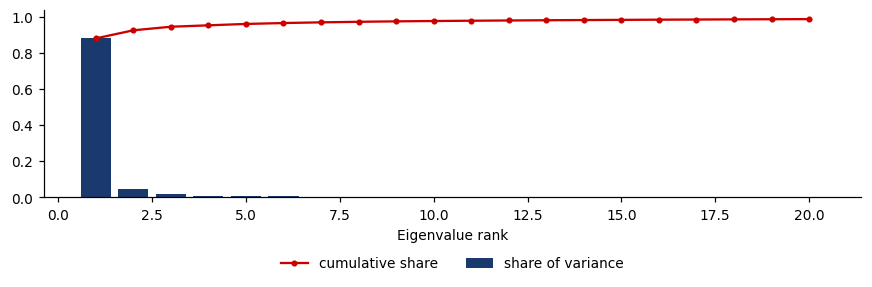

,case,N,V,SR0_ann,DSR
0,N = 120,120.0,V = 1/T,0.770,0.922
1,N = 120,120.0,V din încercări,0.254,0.999
2,N_hat,15.9,V = 1/T,0.533,0.987
3,N_hat,15.9,V din încercări,0.176,1.000
4,95% eigen,4.0,V = 1/T,0.312,0.998
5,95% eigen,4.0,V din încercări,0.103,1.000


In [ ]:
r_b = log_btc.diff()
rets = {}
for fast in range(5, 60, 5):
    for slow in range(20, 260, 20):
        if slow <= fast:
            continue
        ma_f, ma_s = log_btc.rolling(fast).mean(), log_btc.rolling(slow).mean()
        sig = (ma_f > ma_s).astype(float).where(ma_s.notna()).shift(1)   # MA pe log-preț; fără semnal până nu există ambele MA; tranzacționăm a doua zi
        rets[(fast, slow)] = sig * r_b
R = pd.DataFrame(rets).dropna()                                     # start comun: fiecare regulă are semnal valid
print('prima zi a evaluării:', R.index[0].date())
N, T10 = R.shape[1], len(R)
srs = R.mean() / R.std()                                            # SR pe perioadă al fiecărei încercări
best = srs.idxmax()
s_best = R[best]
sk10, ku10 = stats.skew(s_best), stats.kurtosis(s_best, fisher=False)
bh = r_b.loc[R.index]
print(f'N = {N}, T = {T10}; cea mai bună = {best}, SR_ann = {srs[best] * np.sqrt(365):.2f}; '
      f'buy & hold SR_ann = {bh.mean() / bh.std() * np.sqrt(365):.2f}; skew = {sk10:.2f}, kurtosis = {ku10:.1f}')
print(f'PSR(0) = {probabilistic_sharpe_ratio(srs[best], 0, T10, sk10, ku10):.3f}')

C = np.corrcoef(R.values.T)
lam = np.linalg.eigvalsh(C)[::-1]
n_pr = lam.sum() ** 2 / (lam ** 2).sum()
n95 = int(np.searchsorted(np.cumsum(lam) / lam.sum(), 0.95) + 1)
rho_bar = (C.sum() - N) / (N * (N - 1))
n_rho = rho_bar + (1 - rho_bar) * N
print(f'cea mai mare valoare proprie = {lam[0]:.1f} ({lam[0] / lam.sum():.1%}); raport de participare = {n_pr:.2f}; '
      f'95%: {n95}; corelația medie = {rho_bar:.3f} -> N_hat = {n_rho:.1f}')
rows = []
for label, Nx in (('N = 120', N), ('N_hat', n_rho), ('95% eigen', n95)):
    for vlab, sd in (('V = 1/T', np.sqrt(1 / T10)), ('V din încercări', srs.std())):
        rows.append((label, round(Nx, 1), vlab, expected_max_sharpe(max(Nx, 1.0001), sd) * np.sqrt(365),
                     deflated_sharpe_ratio(srs[best], T10, max(Nx, 1.0001), sd, sk10, ku10)))
ex10 = pd.DataFrame(rows, columns=['case', 'N', 'V', 'SR0_ann', 'DSR'])

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(np.arange(1, 21), lam[:20] / lam.sum(), color=MainBlue, label='share of variance')
ax.plot(np.arange(1, 21), np.cumsum(lam[:20]) / lam.sum(), 'o-', ms=3, color=IDAred, label='cumulative share')
ax.set_xlabel('Eigenvalue rank'); legend_bottom(ax, ncol=2)
plt.tight_layout(); plt.show()
ex10.round(3)

## B12 [Propus] — Probabilitatea de overfitting al backtestului (CSCV)

**Cerință.** Împărțiți matricea `R` din B6 (randamentele zilnice ale celor 120 de încercări) în $S = 16$ blocuri contigue. Pentru fiecare
dintre cele $\binom{16}{8} = 12.870$ moduri de a alege 8 blocuri în eșantion (restul în afara lui): alegeți încercarea cu cel mai bun Sharpe
în eșantion, calculați rangul ei relativ $\omega$ în afara eșantionului și logit-ul $\lambda = \ln\frac{\omega}{1-\omega}$. Raportați
$\mathrm{PBO} = P(\lambda \leq 0)$ și Sharpe-ul median în afara eșantionului al cîștigătorului din eșantion.

**Interpretare.** Există overfitting pe grilă? Cum ar schimba PBO alegerea lui $S$ sau adăugarea a 1.000 de strategii aleatoare în grilă?

In [ ]:
# Codul vostru aici


## B13 [Propus] — SPA vs DSR pe grila de 120 de reguli

**Cerință.** Pentru cele 120 de încercări din B6 calculați Reality Check (White), SPA (Hansen, $p$-valoarea cu recentrare consistentă) și
StepM Romano–Wolf (5%) cu bootstrap staționar (bloc mediu de 20 de zile, 2.000 de replici), față de două repere: numerar și buy-and-hold.
Comparați cu DSR din B6 pentru $N = 120$ și $\hat N = 15{,}9$. Model: B6 și B10.

**Interpretare.** Ce metodă tratează încercările corelate fără să aleagă $N$? Bate grila strategia buy-and-hold?

In [ ]:
# Codul vostru aici


## B14 [Propus] — Selecție dublă: prezice Cboe Volatility Index (VIX) randamentele Bitcoin?

**Model.** B10 [Rezolvat] (regresie cu erori HAC); penalizarea și selecția dublă sînt definite mai jos.

**Cerință.** Variabila rezultat: randamentul logaritmic BTC pe 5 zile înainte din B3 (în puncte de bază, bp, basis points; 1 bp = 0,01%; 5 zile calendaristice BTC); regresorul de
interes: log VIX la închiderea din aceeași dată calendaristică, preluat peste weekenduri și sărbătorile din Statele Unite (ultima închidere cunoscută la închiderea zilnică BTC), standardizat; controale: cele 11 caracteristici din B3, pătratele lor și produsele două cîte două ($p = 77$), standardizate.
Penalizarea plug-in a lui Belloni, Chernozhukov & Hansen (2014) este dată ca `rlasso`.

1. Estimați un Least Absolute Shrinkage and Selection Operator (LASSO) pentru $y_t$ pe $(d_t, \mathbf x_t)$ ($d_t$: log VIX, $\mathbf x_t$: controalele): este păstrat VIX?
2. Găsiți $\hat S_y$ și $\hat S_d$, controalele păstrate de un LASSO al lui $y_t$, respectiv al lui $d_t$, pe $\mathbf x_t$.
3. Estimați OLS (Ordinary Least Squares) pentru $y_t$ pe $d_t$ și $\mathbf x_{\hat S_y \cup \hat S_d}$ cu erori HAC (4 laguri): $\hat\theta$ (coeficientul lui $d_t$), SE și intervalul; repetați OLS doar cu VIX și cu toate cele 77 de controale.

**Raportați.** Controalele selectate; un tabel cu $\hat\theta$, SE și intervalul celor trei regresii.

**Interpretare.** De ce nu dă LASSO-ul simplu o inferență validă? Ce spune CI-ul despre o „primă de frică" în cripto?

*Notă.* Ponderile plug-in presupun scoruri independente; cu rezultate suprapuse pe 5 zile, pasul de selecție și intervalul HAC sînt o adaptare
ilustrativă, nu un CI de 95% validat.

In [ ]:
# Codul vostru aici


## C1 [Propus] — Critica unui răspuns AI

**Cerință.** Un asistent AI a răspuns la „prognozează direcția Bitcoin de mîine din randamentele trecute și evaluează în afara eșantionului cu CV în 5 pliuri”
cu codul de mai jos și afirmația „AUC 0,697: un semnal puternic, tranzacționabil; validarea încrucișată este în afara eșantionului, deci nu există overfitting”.
Dați cinci constatări adnotate (numerele liniilor), scrieți un pipeline corectat (caracteristici retrospective, scalarea în pliuri, `TimeSeriesSplit(n_splits=5, gap=20)`)
și un tabel înainte/după cu AUC mediu pe cele 5 pliuri de test, adăugînd cîte o corecție. Treceți erorile ca în `AI_ERRORS.md`.

**Interpretare.** Ce zile intră în `trend10` în ziua $t$? Un AUC neobișnuit de mare este un motiv să verificați codul, nu o dovadă de leakage.

In [ ]:
# Răspunsul AI (dat)
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
r = np.log(btc).diff()
X = pd.DataFrame({'r1': r, 'r5': r.rolling(5).sum(), 'vol20': r.rolling(20).std(),
                  'trend10': r.rolling(10, center=True).mean()})
data = pd.concat([X, r.shift(-1).rename('fwd')], axis=1).dropna()
y = (data['fwd'] > 0).astype(int)
Xs = StandardScaler().fit_transform(data[X.columns])
cv = KFold(n_splits=5, shuffle=True, random_state=0)
model = LogisticRegression(penalty='l1', C=0.1, solver='liblinear')
auc = cross_val_score(model, Xs, y, cv=cv, scoring='roc_auc')
print(round(auc.mean(), 3))

0.697


In [ ]:
# Codul vostru aici


## C2 [Propus] — Bate un model fundațional pentru serii de timp gradient boosting-ul?

**Întrebarea.** Bate un model fundațional pentru serii de timp (Capitolul 14), folosit zero-shot, gradient boosting-ul pentru direcția BTC
la 5 zile, după validare purjată, test Diebold–Mariano și DSR? Nu există o metodă unică: propuneți una și apărați-o.

**Livrabile.** Un folder Quantlet în repo-ul echipei (cod, `Metainfo.txt`, un grafic) și un slide cu concluzia și principala limită.

**Răspunsul trebuie să conțină:** o probabilitate de „sus" derivată din cuantilele prognozate de model, evaluată doar pe date de după datele
de pre-antrenare ale modelului; gradient boosting și prognoza constantă **reestimate la fiecare moment de prognoză** pe o fereastră rolling de lungime
fixă și evaluate exact pe aceleași date (cifrele din B3/B4, obținute prin CV purjat agregat, sînt doar context: pliurile lor de antrenare conțin date
ulterioare); un test Giacomini–White de abilitate predictivă condiționată pe log loss, cu erori HAC; dacă se raportează DSR, regula de poziție
(de exemplu long/cash pentru $P(\text{sus}) > 0{,}5$) și DSR peste *toate* configurațiile încercate.

### C3. Un SDF fără arbitraj pe decile [Propus]

**Întrebarea.** Poate un factor stocastic de actualizare (SDF) liniar, estimat pe portofolii sortate după caracteristici, să depășească portofoliile tangente Fama–French în afara eșantionului?

**Date.** Din [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), folosiți portofoliile de decile ponderate cu valoarea pentru 15 sortări: size, book-to-market, operating profitability, investment, earnings/price, cash flow/price, dividend yield, momentum, short- și long-term reversal, accruals, market beta, net share issues, variance și residual variance. Randamente lunare în exces față de rata Treasury bill la o lună; fișierele FF3 și FF5 (modelele Fama–French cu trei și cinci factori). Salvați [inventarul arhivelor și coloanelor](https://danpele.github.io/MFM/RO/Seminarii/seminar13_machine_learning_ro.pdf#nameddest=sdf-data-manifest).

**Factori.** Pentru fiecare caracteristică, media decilelor 1–5 și media decilelor 6–10 dau 30 de factori $\tilde F_{t+1}$. Păstrați numai lunile cu toate cele 30 de serii și FF5, fără imputare. Salvați panoul și data descărcării. Mediile decilelor ponderate cu valoarea înlocuiesc portofoliile rank-weighted pentru 46 de caracteristici ale acțiunilor: aceasta este o extensie pe portofolii, nu replicarea modelului GAN (Generative Adversarial Network) pe acțiuni individuale.

**Împărțire.** Estimare în 1967–1986, alegerea penalizărilor în 1987–1991, testare în 1992–2016 și din 2017 pînă la ultima lună. Modele de urmat: [A4, inferența pentru Sharpe ratio](https://danpele.github.io/MFM/RO/Seminarii/seminar13_machine_learning_ro.pdf#nameddest=ex-A4) și [B10, teste predictive](https://danpele.github.io/MFM/RO/Seminarii/seminar13_machine_learning_ro.pdf#nameddest=ex-B10), ambele rezolvate.

1. Reproduceți benchmark-urile FF3 și FF5: ponderi tangente $w \propto \hat\Sigma^{-1}\hat\mu$ pe 1967–1986, SR lunar pe 1992–2016 cu CI 95%.
2. Pe 1967–1986, fie $\mu$ media lui $\tilde F$ și $Q$ media lui $\tilde F\tilde F^\top$ (moment de ordinul doi, nu covarianță). Calculați $\hat\theta_{LS}=Q^{-1}\mu$ rezolvînd sistemul, fără inversarea matricei, și $\hat\theta_{EN}=\arg\min_\theta\|\mu-Q\theta\|_2^2+\lambda_2\|\theta\|_2^2+\lambda_1\|\theta\|_1$. Raportați grila $\lambda_1,\lambda_2\ge0$ și alegeți perechea după SR în 1987–1991.
3. Cu ponderile fixate, calculați SR pentru $F=\hat\theta^\top\tilde F$ în ambele perioade de test, diferențele perechi de SR pe aceleași luni (delta method cu HAC sau block bootstrap) și DSR pentru întreaga grilă.
4. Estimați $\hat\beta_i=\overline{R_i^eF}$ pe 1967–1986. În fiecare lună de test proiectați randamentele pe $\hat\beta$: $\hat F_t=\hat\beta^\top R_t^e/(\hat\beta^\top\hat\beta)$, $\hat\epsilon_{t,i}=R_{t,i}^e-\hat\beta_i\hat F_t$. Raportați variația explicată $1-\overline{\hat\epsilon^2}/\overline{(R^e)^2}$ (bara indică media în timp), $R^2$ transversal pe fiecare caracteristică și graficul randamentelor medii realizate față de cele implicate de model.

**Interpretare.** De ce ar putea SDF-ul liniar să depășească o rețea de prognoză? Rezultatul de după 2016 rezistă după luarea în calcul a tuturor configurațiilor încercate?

**Livrabile.** Un folder Quantlet (cod, `Metainfo.txt`, un grafic) și un slide cu concluzia și limita ei.

[Cerința C3 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar13_machine_learning_ro.pdf#nameddest=ex-C3).

In [ ]:
# Codul vostru aici